In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from pathlib import Path
from skimage import io, filters, morphology, measure, segmentation
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# Functions

In [2]:
def show_one_focus(image, df, index, radius_factor=2, padding=30):

    # Select focus by DataFrame index
    row = df.loc[index]

    x = float(row["x_pixel"])
    y = float(row["y_pixel"])
    sigma = float(row["sigma_pixel"])
    sigma_nm = float(row["sigma_nm"])
    foci_MFI = float(row["foci_MFI"])

    # Radius based on sigma
    radius = radius_factor * sigma

    H, W = image.shape[:2]

    # Crop around the focus
    margin = max(padding, int(np.ceil(radius + 10)))

    x0 = max(0, int(x - margin))
    x1 = min(W, int(x + margin + 1))
    y0 = max(0, int(y - margin))
    y1 = min(H, int(y + margin + 1))

    crop = image[y0:y1, x0:x1]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original image
    axes[0].imshow(crop, cmap="gray")
    axes[0].set_title(f"Index: {index}")

    # Image with focus boundary
    axes[1].imshow(crop, cmap="gray")

    circle = Circle(
        (x - x0, y - y0),
        radius=radius,
        edgecolor="red",
        facecolor="none",
        linewidth=1.5
    )

    axes[1].add_patch(circle)

    axes[1].set_title(
        f"Index: {index}\n"
        f"Sigma, nm: {sigma_nm:.2f} nm\n"
        f"Foci MFI: {foci_MFI:.2f}",
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    
def show_selected_foci(
    image,
    df,
    indexes,
    radius_factor=2,
    padding=30
):
    # Allow a single index or a list of indices
    if isinstance(indexes, (int, np.integer)):
        indexes = [indexes]

    # Select foci by DataFrame index
    subset = df.loc[indexes]

    if subset.empty:
        print("No foci selected.")
        return

    H, W = image.shape[:2]
    n = len(subset)

    # Create two panels per focus
    fig, axes = plt.subplots(
        n, 2,
        figsize=(10, 4 * n),
        squeeze=False
    )

    for i, (index, row) in enumerate(subset.iterrows()):

        # Focus properties
        x = float(row["x_pixel"])
        y = float(row["y_pixel"])
        sigma = float(row["sigma_pixel"])
        sigma_nm = float(row["sigma_nm"])
        foci_MFI = float(row["foci_MFI"])

        # Circle radius
        radius = radius_factor * sigma

        # Crop around the focus
        margin = max(padding, int(np.ceil(radius + 10)))

        x0 = max(0, int(np.floor(x - margin)))
        x1 = min(W, int(np.ceil(x + margin + 1)))
        y0 = max(0, int(np.floor(y - margin)))
        y1 = min(H, int(np.ceil(y + margin + 1)))

        crop = image[y0:y1, x0:x1]

        if crop.size == 0:
            print(f"Skipping index {index}: outside image.")
            axes[i, 0].axis("off")
            axes[i, 1].axis("off")
            continue

        # Original image
        axes[i, 0].imshow(crop, cmap="gray")
        axes[i, 0].set_title(
            f"Index: {index}",
            fontsize=11
        )

        # Image with focus boundary
        axes[i, 1].imshow(crop, cmap="gray")

        circle = Circle(
            (x - x0, y - y0),
            radius=radius,
            edgecolor="red",
            facecolor="none",
            linewidth=1.5
        )

        axes[i, 1].add_patch(circle)

        axes[i, 1].set_title(
            f"Index: {index}\n"
            f"Sigma: {sigma_nm:.2f} nm\n"
            f"Foci MFI: {foci_MFI:.2f}",
            fontsize=11
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# Import data

## Import image

Image shape: (512, 512)
Data type: uint16


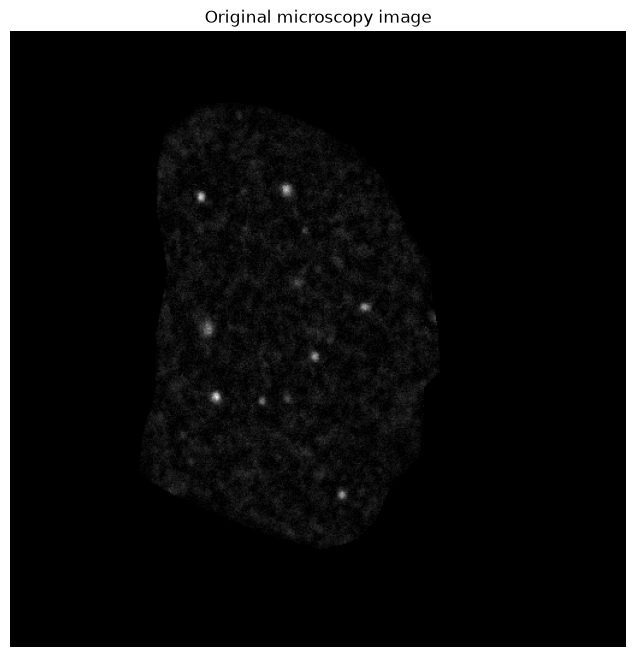

In [3]:
image_path = "0232.tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

## Import ThunderSTORM data

In [4]:
df = pd.read_csv("0232.csv")
df.shape

(436, 10)

## Visualization

In [5]:
df.head()

,id,x_nm,y_nm,sigma_nm,intensity_photon,x_pixel,y_pixel,sigma_pixel,foci_MFI,foci_SD
0,2.0,6804.364548,19433.395064,92.211520,236.599400,113.245267,332.710741,1.602439,9.000000,3.500000
1,4.0,7131.746771,21538.294151,98.110050,348.711934,118.934468,369.289374,1.704942,6.555556,3.435472
2,6.0,6958.869510,19359.943673,98.207920,281.975044,115.930232,331.434313,1.706643,9.500000,3.278719
3,7.0,7194.146240,19868.798015,100.573200,262.941233,120.018837,340.277111,1.747747,7.800000,4.664762
4,8.0,7097.804814,20462.558376,99.397913,323.333310,118.344630,350.595393,1.727323,8.727273,4.992556


In [6]:
df.describe()

,id,x_nm,y_nm,sigma_nm,intensity_photon,x_pixel,y_pixel,sigma_pixel,foci_MFI,foci_SD
count,436.000000,436.000000,436.000000,436.000000,436.000000,436.000000,436.000000,436.000000,436.000000,436.000000
mean,396.422018,13336.552191,14593.412837,111.426869,554.566842,226.760684,248.602227,1.936360,14.688353,6.001998
std,235.050439,3737.691393,5513.838309,32.813343,746.481587,64.953063,95.818688,0.570226,9.599351,3.078822
min,2.000000,6804.364548,3932.942994,75.027104,96.130382,113.245267,63.346117,1.303810,5.142857,2.291288
25%,182.500000,10066.227245,10014.186534,90.369566,269.026139,169.929448,169.025092,1.570429,10.642857,4.561283
50%,390.000000,13239.048649,14765.919952,101.769097,377.139765,225.066281,251.600031,1.768529,13.404762,5.539334
75%,585.500000,16170.080285,19242.045337,119.876163,546.123866,276.001327,329.385493,2.083191,16.314103,6.675542
max,799.000000,20579.870394,24853.503074,247.392218,8677.325429,352.634024,426.900598,4.299146,101.500000,33.806656


In [ ]:
# inxs = list(df[(df['sigma_nm'] > 120) & (df['foci_MFI'] > 12)].index)

In [11]:
inxs = list(df[(df['sigma_nm'] < 90)].index)



In [12]:
show_selected_foci(
    image,
    df,
    indexes=inxs,
    padding=50,
)

In [ ]:
#i = 102

#show_one_focus(image, df, index=i, padding=70)

# Random Forest

## Import labelled data

In [17]:
df1 = pd.read_csv("training_data/0220_labelled.csv",  sep=";", encoding="cp1252")
df2 = pd.read_csv("training_data/0232_labelled.csv",  sep=";", encoding="cp1252")


In [23]:
dfs = [df1, df2]

df_combined = pd.concat(dfs, ignore_index=True)

df = df_combined[
    df_combined["Class"].isin(["foci", "aggregate"])
].reset_index(drop=True)

df.shape

(49, 16)

In [25]:
df.head()

,index,id,x_nm,y_nm,sigma_nm,intensity_photon,x_pixel,y_pixel,sigma_pixel,foci_MFI,foci_SD,Class,Unnamed: 12,Unnamed: 13,Index,Unnamed: 11
0,2.0,5.0,3593.493377,14143.423979,203.208099,980.417462,57.447210,240.782385,3.531321,9.526315789473683,3.4007494692947597,aggregate,NaN,NaN,NaN,NaN
1,4.0,7.0,3753.033031,13521.815213,97.273987,291.823974,60.219668,229.980158,1.690413,14.77777777777778,1.617802197617893,aggregate,NaN,`,NaN,NaN
2,5.0,9.0,4073.929339,15960.421115,188.574352,1102.988950,65.796157,272.357900,3.277018,11.685714285714283,5.063998581422892,aggregate,NaN,NaN,NaN,NaN
3,22.0,46.0,5741.356180,17198.851976,163.410009,827.739099,94.772461,293.879173,2.839716,10.208333333333334,5.686088042074465,aggregate,NaN,NaN,NaN,NaN
4,50.0,134.0,7870.722091,14439.800156,100.612415,314.916233,131.776275,245.932768,1.748428,14.22222222222222,3.705184889007348,foci,NaN,NaN,NaN,NaN


In [26]:
df.columns

Index(['index', 'id', 'x_nm', 'y_nm', 'sigma_nm', 'intensity_photon',
       'x_pixel', 'y_pixel', 'sigma_pixel', 'foci_MFI', 'foci_SD', 'Class',
       'Unnamed: 12', 'Unnamed: 13', 'Index', 'Unnamed: 11'],
      dtype='str')

In [27]:
# Features for classification
features = [
    "sigma_nm",
    "foci_MFI",
    "foci_SD"
]

# Copy original DataFrame
data = df.copy()

# Clean class labels
data["Class"] = (
    data["Class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert features to numeric
for feature in features:
    data[feature] = pd.to_numeric(
        data[feature],
        errors="coerce"
    )

# Manually labeled objects
labeled = data[
    data["Class"].isin(["foci", "aggregate"])
].dropna(subset=features).copy()

print("Training samples:")
print(labeled["Class"].value_counts())

Training samples:
Class
foci         25
aggregate    21
Name: count, dtype: Int64


In [28]:
# Model training
X = labeled[features]
y = labeled["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

## Evaluate classifier

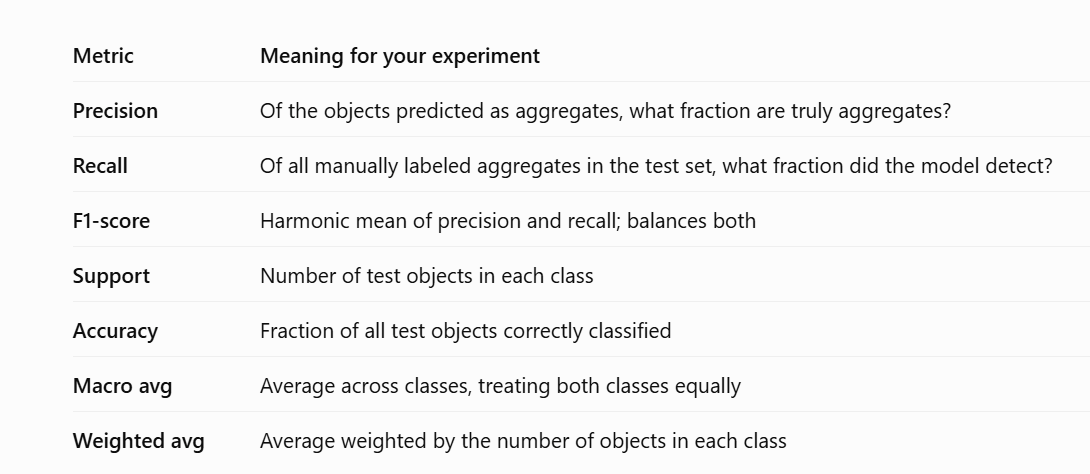

              precision    recall  f1-score   support

   aggregate       0.67      0.80      0.73         5
        foci       0.83      0.71      0.77         7

    accuracy                           0.75        12
   macro avg       0.75      0.76      0.75        12
weighted avg       0.76      0.75      0.75        12



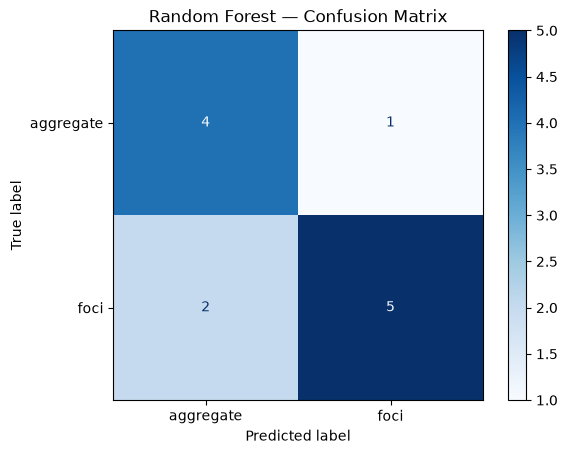

In [29]:
y_pred = rf.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Random Forest — Confusion Matrix")
plt.show()

## Identify the most important features

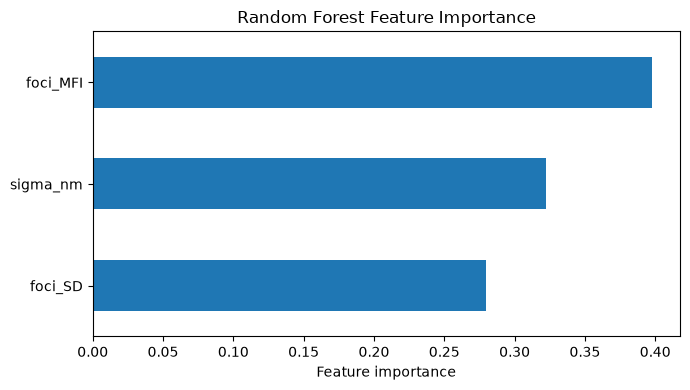

In [30]:
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))

importance.plot.barh(ax=ax)

ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

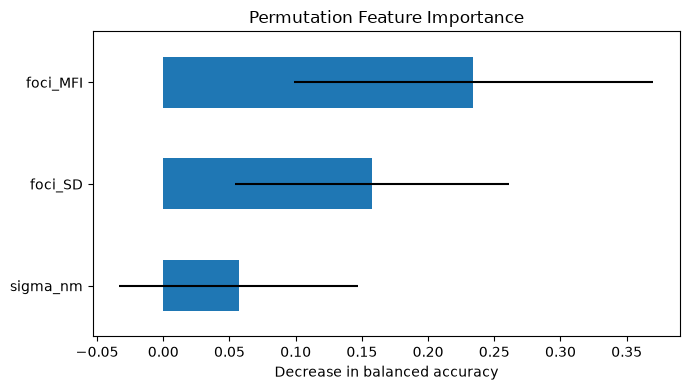

In [31]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="balanced_accuracy"
)

importance = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values()

importance.plot.barh(
    xerr=result.importances_std[
        [list(X_test.columns).index(f) for f in importance.index]
    ],
    figsize=(7, 4)
)

plt.xlabel("Decrease in balanced accuracy")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

## Correlation analysis

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ["sigma_nm", "foci_MFI", "foci_SD"]

sns.heatmap(
    labeled[features].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Feature correlations")
plt.show()

In [ ]:
# Select objects that were not manually classified
unknown_mask = ~data["Class"].isin(["foci", "aggregate"])

# Only predict objects with valid measurements
valid_mask = data[features].notna().all(axis=1)

predict_mask = unknown_mask & valid_mask

X_unknown = data.loc[predict_mask, features]

# Predicted classes
data["Predicted_Class"] = data["Class"]

data.loc[predict_mask, "Predicted_Class"] = rf.predict(
    X_unknown
)

# Prediction probabilities
probabilities = rf.predict_proba(X_unknown)

data["Confidence"] = np.nan

data.loc[predict_mask, "Confidence"] = probabilities.max(axis=1)

display(
    data[["Class", "Predicted_Class", "Confidence"]].head(20)
)

In [ ]:
data["Review"] = False

data.loc[predict_mask, "Review"] = (
    data.loc[predict_mask, "Confidence"] < 0.8
)

display(
    data.loc[
        data["Review"],
        ["Predicted_Class", "Confidence"] + features
    ]
)

In [ ]:
def plot_rf_predictions(image, data):

    colors = {
        "foci": "lime",
        "aggregate": "red"
    }

    fig, ax = plt.subplots(figsize=(10, 10))

    ax.imshow(image, cmap="gray")

    for class_name, color in colors.items():

        subset = data[
            data["Predicted_Class"] == class_name
        ]

        ax.scatter(
            subset["x_pixel"],
            subset["y_pixel"],
            s=50,
            facecolors="none",
            edgecolors=color,
            linewidths=1.2,
            label=f"{class_name}: {len(subset)}"
        )

    ax.legend()
    ax.set_title("Random Forest classification")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
plot_rf_predictions(image, data)